In [30]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch


words = open('names.txt', 'r').read().splitlines()

sorted_chars = sorted(list(set(''.join(words))))
enumerated = enumerate(sorted_chars)
char_to_idx = {char: idx + 1 for idx, char in enumerated}
char_to_idx['.'] = 0
idx_to_char = {idx: char for char, idx in char_to_idx.items()}

print(char_to_idx)
print(idx_to_char)
print(len(words))

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
32033


In [31]:
import random
def construct_dataset(words, block_size):
  X, Y = [], []
  for word in words:
    context = [0] * block_size
    for ch in word + '.':
      X.append(context)
      idx = char_to_idx[ch]
      Y.append(idx)
      context = context[1:] + [idx]
  return torch.tensor(X), torch.tensor(Y)

random.seed(42)
random.shuffle(words)
num_words = len(words)
training_size = int(0.8 * num_words)
validation_size = int(0.1 * num_words)
test_size = num_words - training_size - validation_size
block_size = 5

X_train, Y_train = construct_dataset(words[:training_size], block_size)
X_val, Y_val = construct_dataset(words[training_size:training_size + validation_size], block_size)
X_test, Y_test = construct_dataset(words[training_size + validation_size:], block_size)

print(X_train.shape, Y_train.shape)
print(X_val.shape, Y_val.shape)
print(X_test.shape, Y_test.shape)

torch.Size([182625, 5]) torch.Size([182625])
torch.Size([22655, 5]) torch.Size([22655])
torch.Size([22866, 5]) torch.Size([22866])


In [ ]:
g = torch.Generator().manual_seed(2147483647)
embedding_dimension = 10
invisible_layer_dimension = 200
char_dimension = 27
mat_dimension = block_size * embedding_dimension

#Random initialisation
C = torch.randn((char_dimension, embedding_dimension), generator=g)
W1 = torch.randn((mat_dimension, invisible_layer_dimension), generator=g) * (5 / 3) / (mat_dimension ** (1 / 2))
b1 = torch.randn(invisible_layer_dimension, generator=g) * 0.01
W2 = torch.randn((invisible_layer_dimension, char_dimension), generator=g) * 0.01
b2 = torch.randn(char_dimension, generator=g) * 0.01

gain = torch.ones((1, invisible_layer_dimension))
bias = torch.zeros((1, invisible_layer_dimension))


embeddings = C[X_train]
h = torch.tanh(embeddings.view(-1, mat_dimension) @ W1)

parameters = [C, W1, b1, W2, b2, gain, bias]
num_params = [sum(p.nelement() for p in parameters)]
print(num_params)
for p in parameters:
  p.requires_grad = True

global_mean, global_std = h.mean(), h.std()

print(W1.shape, b1.shape, W2.shape, b2.shape)

[16297]
torch.Size([50, 200]) torch.Size([200]) torch.Size([200, 27]) torch.Size([27])


In [ ]:
sample_size = 50
step = []
loss_values = []
for i in range(500000):
  ## sample random entries from dataset

  ix = torch.randint(0, X_train.shape[0], (sample_size,))

  emb = C[X_train[ix]]
  input_to_tan_layer = emb.view(-1, mat_dimension) @ W1 + b1
  mean, std = input_to_tan_layer.mean(0, keepdim=True), input_to_tan_layer.std(0, keepdim=True)

  with torch.no_grad():
    global_mean, global_std = global_mean * 0.99 + mean * 0.01, global_std * 0.99 + std * 0.01

  input_to_tan_layer = gain * (input_to_tan_layer - mean) / std + bias
  h = torch.tanh(input_to_tan_layer)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Y_train[ix])
  print(loss.item())

  for p in parameters:
    p.grad = None
  loss.backward()

  learning_rate = 0.1 if i < 500000 else 0.01

  for p in parameters:
    p.data += -learning_rate * p.grad

  step.append(i)
  loss_values.append(loss.log10().item())

#print(h)

Streaming output truncated to the last 5000 lines.
2.107365369796753
2.0881807804107666
1.965179443359375
2.0366759300231934
1.9460270404815674
2.0417535305023193
1.7499101161956787
2.0027589797973633
2.392449378967285
1.8173670768737793
2.004761219024658
1.994123935699463
1.9918485879898071
1.84800124168396
2.15114688873291
2.215696334838867
1.688657283782959
1.9999417066574097
1.9760414361953735
1.8227317333221436
1.9451050758361816
2.450523614883423
2.0792086124420166
1.838913917541504
2.4268691539764404
2.0986757278442383
1.9331625699996948
2.0327560901641846
1.8868117332458496
1.7733864784240723
1.599112868309021
2.059455633163452
1.9191937446594238
1.9059802293777466
1.4833842515945435
1.6162043809890747
1.9711236953735352
1.9305652379989624
1.5891956090927124
1.7738476991653442
2.07920241355896
1.960302710533142
1.8044297695159912
1.9785531759262085
1.8444818258285522
1.9800289869308472
1.8987109661102295
2.17891788482666
2.110750198364258
1.8265776634216309
1.8293946981430054
1

(array([2505.,  270.,  210.,  152.,  136.,  110.,  100.,   89.,   96.,
          73.,   75.,   62.,   76.,   66.,   65.,   56.,   60.,   60.,
          62.,   61.,   54.,   82.,   75.,   71.,   76.,   99.,   76.,
          93.,   84.,   64.,   84.,   71.,   68.,   85.,   70.,   72.,
          64.,   72.,   66.,   72.,   80.,   75.,   74.,  119.,  137.,
         132.,  162.,  184.,  352., 2803.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

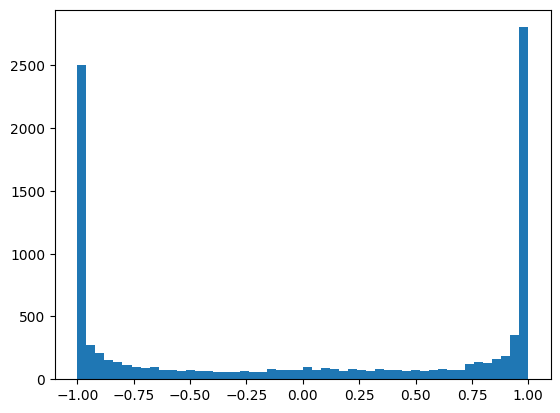

In [ ]:
plt.hist(h.view(-1).tolist(), bins=50)

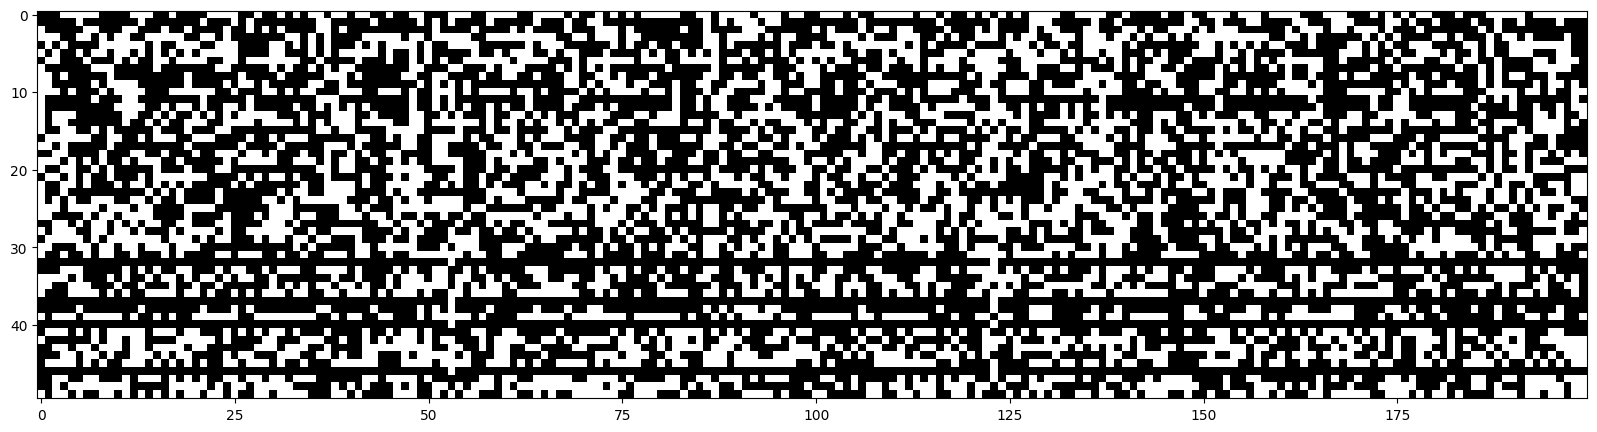

In [ ]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

In [ ]:
@torch.no_grad()
def evaluate_loss(X, Y):
  emb = C[X]
  input_to_tan_layer = emb.view(-1, mat_dimension) @ W1 + b1
  input_to_tan_layer = gain * (input_to_tan_layer - global_mean) / global_std + bias
  h = torch.tanh(input_to_tan_layer)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Y)
  return loss.item()

print("Training loss -> ", evaluate_loss(X_train, Y_train))
print("Dev loss -> ", evaluate_loss(X_val, Y_val))
print("Test loss -> ", evaluate_loss(X_test, Y_test))

Training loss ->  1.9448939561843872
Dev loss ->  2.0662331581115723
Test loss ->  2.0645382404327393


In [ ]:
g = torch.Generator().manual_seed(2147483647)
for i in range(10):
  context = [0] * block_size
  word_idx = []
  while True:
    embedding = C[torch.tensor([context])]
    h = torch.tanh(embedding.view(1, -1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
    word_idx.append(ix)
    context = context[1:] + [ix]
    if ix == 0:
      break
  print(''.join(idx_to_char[i] for i in word_idx))

celberto.
journie.
zolah.
mellie.
teal.
jakayla.
andr.
samiyah.
javer.
gotsi.


In [ ]:
logits = torch.zeros(5)
probs = torch.softmax(logits, dim=0)
nll = [-1 * x.log() for x in probs]
print(nll)

[tensor(1.6094), tensor(1.6094), tensor(1.6094), tensor(1.6094), tensor(1.6094)]


In [32]:
g = torch.Generator().manual_seed(2147483647)
class Linear:
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in ** 0.5
    self.bias = torch.zeros(fan_out) if bias else None

  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self):
    return [self.weight] + ([self.bias] if self.bias else [])




class Tanh:
  def __init__(self):
    pass

  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out

  def parameters(self):
    return []


class BatchNorm:

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True

    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)

    self.running_mean = torch.zeros(dim)
    self.running_var = torch.zeros(dim)


  def __call__(self, x):
    if self.training:
      xmean = x.mean(0, keepdim=True)
      xvar = x.var(0, keepdim=True)
    else:
      xmean = self.running_mean
      xvar = self.running_var

    xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
    self.out = self.gamma * xhat + self.beta

    if self.training:
      with torch.torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

    return self.out

  def parameters(self):
    return [self.gamma, self.beta]


In [33]:
embedding_dimension = 10
invisible_layer_dimension = 200
char_dimension = 27
block_size = 5

g = torch.Generator().manual_seed(2147483647)

C = torch.randn((char_dimension, embedding_dimension), generator=g)
layers = [
    Linear(embedding_dimension * block_size, invisible_layer_dimension, bias=False), BatchNorm(invisible_layer_dimension), Tanh(),
    Linear(invisible_layer_dimension, invisible_layer_dimension, bias=False), BatchNorm(invisible_layer_dimension), Tanh(),
    Linear(invisible_layer_dimension, invisible_layer_dimension, bias=False), BatchNorm(invisible_layer_dimension), Tanh(),
    Linear(invisible_layer_dimension, invisible_layer_dimension, bias=False), BatchNorm(invisible_layer_dimension), Tanh(),
    Linear(invisible_layer_dimension, char_dimension, bias=False), BatchNorm(char_dimension)
]

with torch.no_grad():
  layers[-1].gamma *= 0.1
  for layer in layers:
    if isinstance(layer, Linear):
      layer.weight *= 5 / 3
parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True


137324


In [39]:
sample_size = 50
step = []
loss_values = []
ud = []
max_steps = 100000

for i in range(max_steps):
  ## sample random entries from dataset

  ix = torch.randint(0, X_train.shape[0], (sample_size,))

  emb = C[X_train[ix]]
  current = emb.view(-1, embedding_dimension * block_size)
  for layer in layers:
    current = layer(current)

  loss = F.cross_entropy(current, Y_train[ix])

  for layer in layers:
    layer.out.retain_grad()

  for p in parameters:
    p.grad = None
  loss.backward()

  learning_rate = 0.1 if i < 500000 else 0.01

  for p in parameters:
    p.data += -learning_rate * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  loss_values.append(loss.log10().item())
  with torch.no_grad():
    ud.append([((learning_rate*p.grad).std() / p.data.std()).log10().item() for p in parameters])

  # if i >= 1000:
  #   break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 100000: 2.6147
  10000/ 100000: 2.3613
  20000/ 100000: 2.0353
  30000/ 100000: 1.9199
  40000/ 100000: 1.7715
  50000/ 100000: 1.8309
  60000/ 100000: 1.7791
  70000/ 100000: 1.8896
  80000/ 100000: 1.8628
  90000/ 100000: 1.8410


layer 2 (      Tanh): mean +0.00, std 0.70, saturated: 15.17%
layer 5 (      Tanh): mean +0.00, std 0.75, saturated: 19.39%
layer 8 (      Tanh): mean +0.00, std 0.77, saturated: 21.47%
layer 11 (      Tanh): mean +0.00, std 0.79, saturated: 24.96%


Text(0.5, 1.0, 'activation distribution')

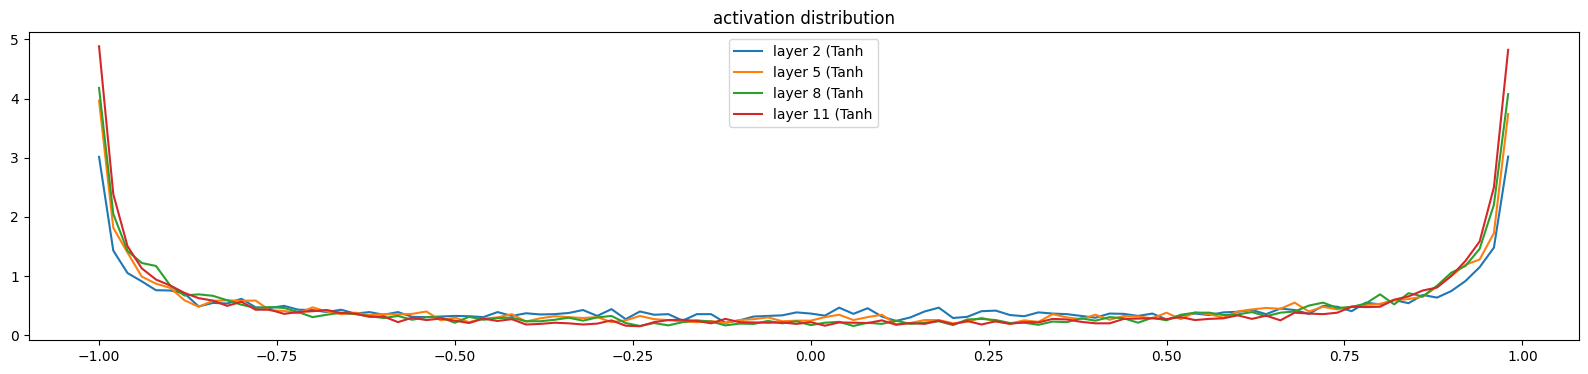

In [40]:
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean +0.000000, std 2.296090e-03
layer 5 (      Tanh): mean +0.000000, std 2.255465e-03
layer 8 (      Tanh): mean +0.000000, std 2.259295e-03
layer 11 (      Tanh): mean +0.000000, std 2.062418e-03


Text(0.5, 1.0, 'gradient distribution')

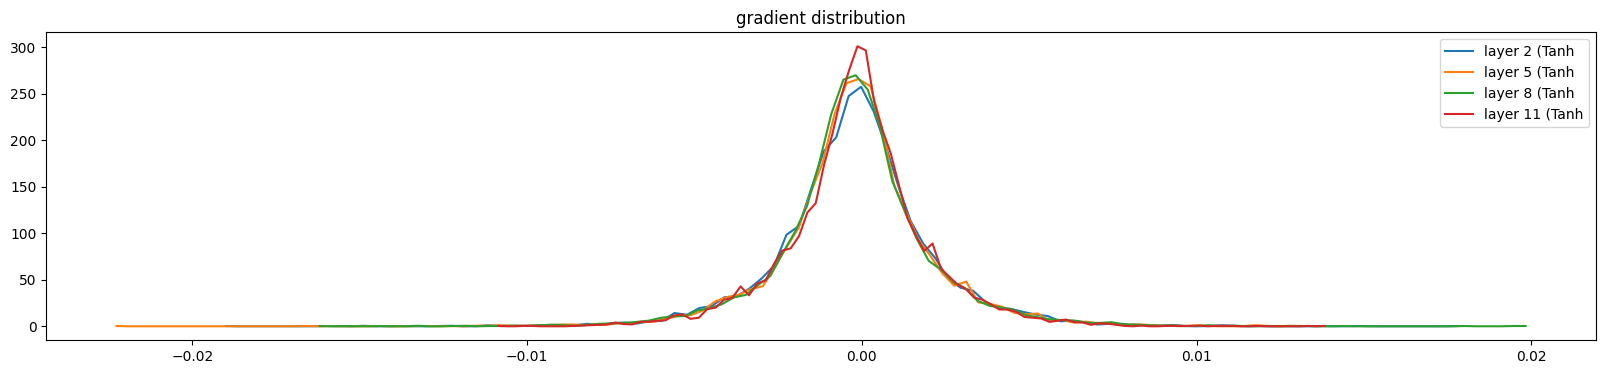

In [41]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

weight   (27, 10) | mean -0.000000 | std 1.639495e-02 | grad:data ratio 1.484694e-02
weight  (50, 200) | mean -0.000120 | std 6.557020e-03 | grad:data ratio 2.123253e-02
weight (200, 200) | mean +0.000005 | std 4.356522e-03 | grad:data ratio 2.459600e-02
weight (200, 200) | mean +0.000000 | std 4.316665e-03 | grad:data ratio 2.460010e-02
weight (200, 200) | mean -0.000009 | std 3.798947e-03 | grad:data ratio 2.299471e-02
weight  (200, 27) | mean +0.000032 | std 6.868684e-03 | grad:data ratio 2.466339e-02


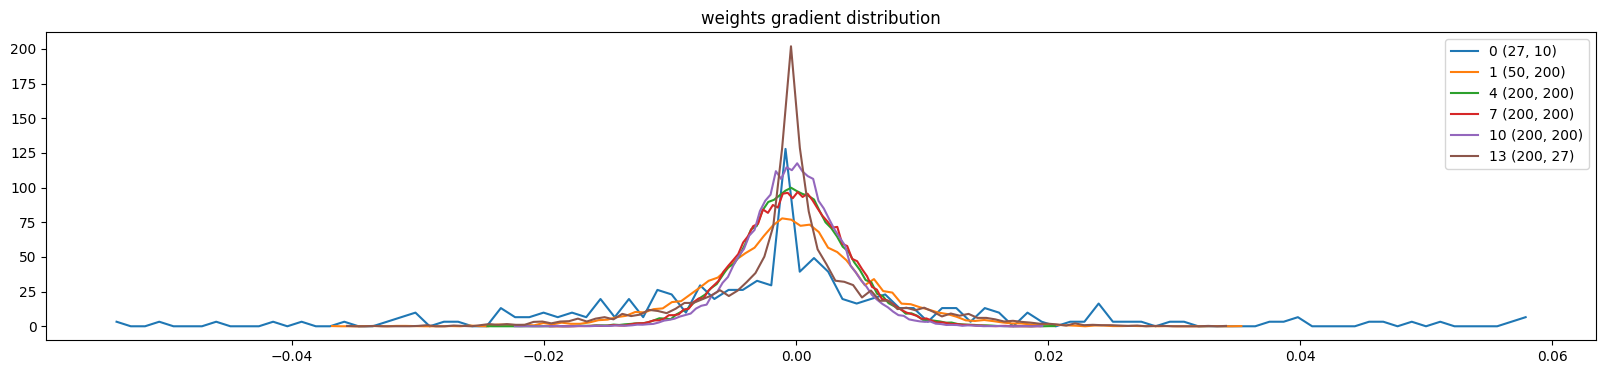

In [42]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

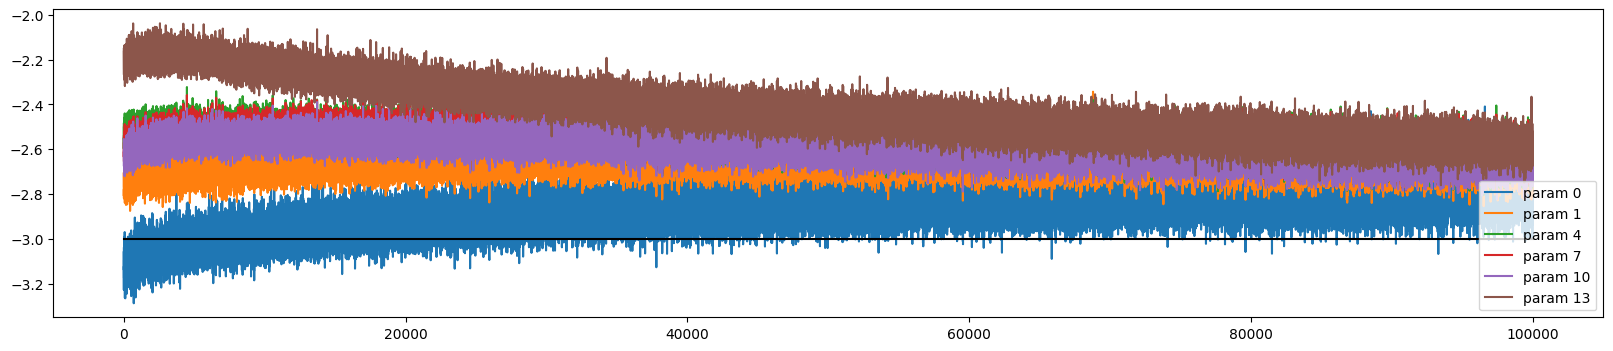

In [43]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

In [44]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (X_train, Y_train),
    'val': (X_val, Y_val),
    'test': (X_test, Y_test),
  }[split]
  emb = C[x] # N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 1.7924741506576538
val 2.024007797241211


In [45]:
for layer in layers:
    layer.training = False

for i in range(10):
  context = [0] * block_size
  word_idx = []
  while True:
    embedding = C[torch.tensor([context])]
    input = embedding.view(embedding.shape[0], -1)
    for layer in layers:
      input = layer(input)
    probs = F.softmax(input, dim=1)
    ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
    word_idx.append(ix)
    context = context[1:] + [ix]
    if ix == 0:
      break
  print(''.join(idx_to_char[i] for i in word_idx))

tiak.
rayiah.
freider.
ivare.
kashika.
harlester.
redget.
kaohd.
serapker.
lyndell.


In [74]:
### Exercise 2 - create simple 3 layer MLP and fold gamma/beta of BatchNorm layer into weights and biases of preceiding layer
embedding_dimension = 10
invisible_layer_dimension = 200
char_dimension = 27
block_size = 5

g = torch.Generator().manual_seed(2147483647)

C = torch.randn((char_dimension, embedding_dimension), generator=g)
layers = [
    Linear(embedding_dimension * block_size, invisible_layer_dimension, bias=False), BatchNorm(invisible_layer_dimension), Tanh(),
]

with torch.no_grad():
  layers[-2].gamma *= 0.1
  for layer in layers:
    if isinstance(layer, Linear):
      layer.weight *= 5 / 3
parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

10670


In [75]:
#### Train this model using
sample_size = 50
step = []
loss_values = []
ud = []
max_steps = 100000

for i in range(max_steps):
  ## sample random entries from dataset

  ix = torch.randint(0, X_train.shape[0], (sample_size,))

  emb = C[X_train[ix]]
  current = emb.view(-1, embedding_dimension * block_size)
  for layer in layers:
    current = layer(current)

  loss = F.cross_entropy(current, Y_train[ix])

  for layer in layers:
    layer.out.retain_grad()

  for p in parameters:
    p.grad = None
  loss.backward()

  learning_rate = 0.1 if i < 500000 else 0.01

  for p in parameters:
    p.data += -learning_rate * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  loss_values.append(loss.log10().item())
  with torch.no_grad():
    ud.append([((learning_rate*p.grad).std() / p.data.std()).log10().item() for p in parameters])

      0/ 100000: 5.3042
  10000/ 100000: 3.7949
  20000/ 100000: 3.7675
  30000/ 100000: 3.7026
  40000/ 100000: 3.7717
  50000/ 100000: 3.7130
  60000/ 100000: 3.7456
  70000/ 100000: 3.7760
  80000/ 100000: 3.6556
  90000/ 100000: 3.7081


In [76]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (X_train, Y_train),
    'val': (X_val, Y_val),
    'test': (X_test, Y_test),
  }[split]
  emb = C[x] # N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 3.7146427631378174
val 3.7180657386779785


In [77]:
#### Fold gamma and beta of batch norm layer into weights and bias of preceding linear layer
linear_first = layers[0]
batch_first = layers[1]

linear_first.weight = linear_first.weight * batch_first.gamma
linear_first.bias = batch_first.beta

layers = [layers[0]] + layers[2:]

#### Now calculate validation loss
split_loss('val')


val 3.80790114402771


In [60]:
print(layers[0])